In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

In [2]:
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")

print("Dataset Shape:", df.shape)
print(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (2823, 25)
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue

In [3]:
# Select numerical features for clustering
X = df[[
    "SALES",
    "QUANTITYORDERED",
    "PRICEEACH",
    "MSRP"
]]

# Remove missing values
X = X.dropna()

# Feature scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Preprocessing Completed")
print("Scaled Data Shape:", X_scaled.shape)

Preprocessing Completed
Scaled Data Shape: (2823, 4)


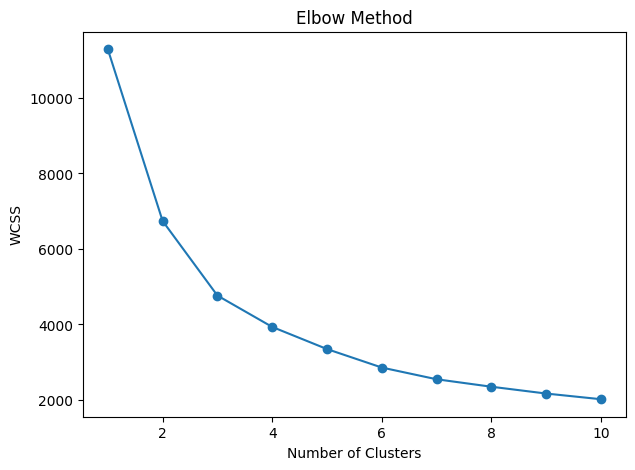

In [4]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(range(1, 11), wcss, marker='o')

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()

In [5]:
k = 3

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

df = df.loc[X.index].copy()
df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print(df[["SALES", "QUANTITYORDERED",
          "KMeans_Cluster"]].head())

print("\nCluster Counts:")
print(df["KMeans_Cluster"].value_counts())

     SALES  QUANTITYORDERED  KMeans_Cluster
0  2871.00               30               2
1  2765.90               34               2
2  3884.34               41               1
3  3746.70               45               1
4  5205.27               49               1

Cluster Counts:
KMeans_Cluster
2    996
0    975
1    852
Name: count, dtype: int64


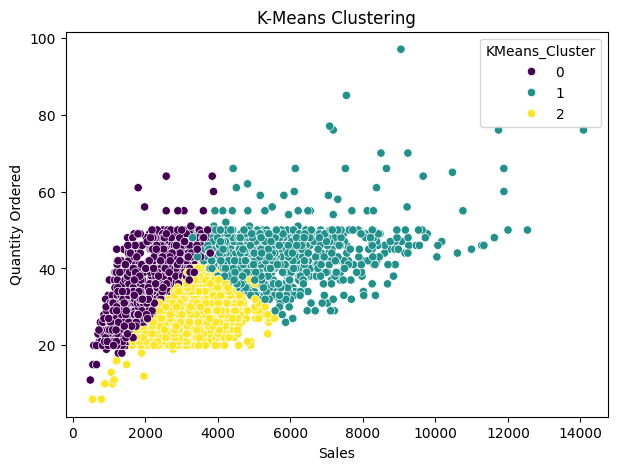

In [6]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    x=df["SALES"],
    y=df["QUANTITYORDERED"],
    hue=df["KMeans_Cluster"],
    palette="viridis"
)

plt.title("K-Means Clustering")
plt.xlabel("Sales")
plt.ylabel("Quantity Ordered")
plt.show()